# Pantallas, ansiedad y gemelos idénticos

**0,38 → 0,02.** Eso es lo que queda de la asociación entre pasar más de 6 horas al día entre semana frente a una pantalla interactiva y los síntomas de ansiedad y depresión a los 15 años, cuando comparamos a cada adolescente con su gemelo idéntico. ¿Se esfumó la asociación, o era en parte cosa de familia?

**Paper:** Gong et al. (2026). *Recreational screen use and internalizing problems from preadolescence to young adulthood in a longitudinal twin cohort with co-twin comparison*. **Nature Human Behaviour**.
**DOI:** [10.1038/s41562-026-02607-0](https://doi.org/10.1038/s41562-026-02607-0)

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ciencia-a-Mordiscos/lab/blob/main/papers/2026-10-08-pantallas-gemelos-ansiedad-depresion/notebook.ipynb)

**Video:** Pendiente

## El grupo de control que la naturaleza ya armó

El equipo siguió a **21.797 gemelos suecos** (cohorte CATSS, el gran estudio sueco de gemelos en la infancia y la adolescencia) con entrevistas y cuestionarios desde los 9 años hasta los 24, preguntando cuánto tiempo pasaban frente a pantallas y midiendo síntomas de ansiedad y depresión. Además cruzaron los registros sanitarios de Suecia para contar diagnósticos clínicos.

El truco está en comparar gemelos entre sí (diseño *co-twin control*). Los gemelos idénticos (monocigóticos, MZ) comparten todos sus genes y su hogar; los mellizos (dicigóticos, DZ) comparten el hogar y, en promedio, la mitad de los genes. Si el gemelo que usa más pantallas tiene más síntomas que su propio gemelo idéntico, ni los genes ni el hogar que comparten pueden explicar esa diferencia (lo que no comparten, todavía sí).

Los microdatos individuales están protegidos por ley. Lo que sí es público son las **27 tablas suplementarias** del paper, con todos los coeficientes, intervalos de confianza y conteos. Con ellas trabajamos aquí.

In [1]:
# ══════════════════════════════════════════════════════════════
# Configuración — modifica estos valores para explorar
# ══════════════════════════════════════════════════════════════
NIVEL = '>6 hours/day'      # nivel de uso frente a <2 h/día: '2-4 hours/day', '4-6 hours/day', '>6 hours/day'
TIPO = 'interactivo'        # 'interactivo' (juegos, chat, internet) o 'pasivo' (TV, video)
UMBRAL_BY = 0.00133         # umbral de p tras la corrección por pruebas múltiples (Benjamini-Yekutieli) del paper
FUENTE = 'Fuente: Gong et al. (2026), Nature Human Behaviour | Datos: tablas suplementarias (MOESM4)'
COLOR_DATOS = '#2563EB'
COLOR_ALERTA = '#DC2626'
COLOR_REFERENCIA = '#D97706'
COLOR_SECUNDARIO = '#059669'
COLOR_CONTEXTO = '#BBBBBB'

import os, re, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

BASE = 'https://raw.githubusercontent.com/Ciencia-a-Mordiscos/lab/main/papers/2026-10-08-pantallas-gemelos-ansiedad-depresion'
ARCHIVOS = ['transversal_beta.csv', 'transversal_por_sexo.csv', 'entre_edades_beta.csv',
            'clinico_hr.csv', 'correlaciones_gemelos.csv', 'uso_por_sexo.csv']
os.makedirs('datos', exist_ok=True)
os.makedirs('figuras', exist_ok=True)
for a in ARCHIVOS:
    if not os.path.exists(f'datos/{a}'):
        urllib.request.urlretrieve(f'{BASE}/datos/{a}', f'datos/{a}')

style_file = '../../cam.mplstyle'
if not os.path.exists(style_file):
    style_file = '/tmp/cam.mplstyle'
    if not os.path.exists(style_file):
        urllib.request.urlretrieve('https://raw.githubusercontent.com/Ciencia-a-Mordiscos/lab/main/cam.mplstyle', style_file)
plt.style.use(style_file)

# Números en formato español: coma decimal, punto de miles
def es(x):
    s = str(x)
    s = re.sub(r'(?<=\d)\.(?=\d)', ',', s)
    return s.replace('_', '.')

def pr(*a):
    print(*[es(x) for x in a])

COMA = FuncFormatter(lambda v, _: es(f'{v:g}'))

# Traducción de etiquetas de las tablas
DESENLACE = {'Depression/anxiety symptoms (SDQ emotion subscale)': 'ánimo/ansiedad (SDQ)',
             'Depression symptoms (CESD)': 'depresión (CESD)',
             'Anxiety symptoms (SCARED)': 'ansiedad (SCARED)',
             'Depression symptoms (SMFQ)': 'depresión (SMFQ)'}
DIA = {'lun-vie': 'lun-vie', 'sab-dom': 'sáb-dom', 'sin_distincion': ''}

trans = pd.read_csv('datos/transversal_beta.csv')
sexo = pd.read_csv('datos/transversal_por_sexo.csv')
entre = pd.read_csv('datos/entre_edades_beta.csv')
clin = pd.read_csv('datos/clinico_hr.csv')
corr = pd.read_csv('datos/correlaciones_gemelos.csv')

pr('Gemelos analizados por edad (modelo sin ajustar):')
for edad, n in trans[trans.modelo == 'todos_crudo'].groupby('edad').n_modelo.max().items():
    pr(f'  {edad} años: {n:_}')

# ¿Por qué funciona el diseño? Los idénticos se parecen más que los mellizos en todo
w = corr[corr.tipo_par.isin(['MZ', 'DZ'])].pivot_table(index=['edad', 'rasgo'], columns='tipo_par', values='r')
pr(f'Correlación entre gemelos MZ > DZ en {(w.MZ > w.DZ).sum()} de {len(w)} rasgos (uso de pantallas y síntomas)')
p15 = corr[(corr.edad == 15) & (corr.clase == 'pantalla')]
pr(f'  Pantallas a los 15: MZ {p15[p15.tipo_par == "MZ"].r.min():.2f}–{p15[p15.tipo_par == "MZ"].r.max():.2f}'
   f'  vs  DZ {p15[p15.tipo_par == "DZ"].r.min():.2f}–{p15[p15.tipo_par == "DZ"].r.max():.2f}')

Gemelos analizados por edad (modelo sin ajustar):
  9 años: 21.797
  15 años: 16.027
  18 años: 13.050
Correlación entre gemelos MZ > DZ en 19 de 19 rasgos (uso de pantallas y síntomas)
  Pantallas a los 15: MZ 0,49–0,64  vs  DZ 0,23–0,33


## Aquí está.

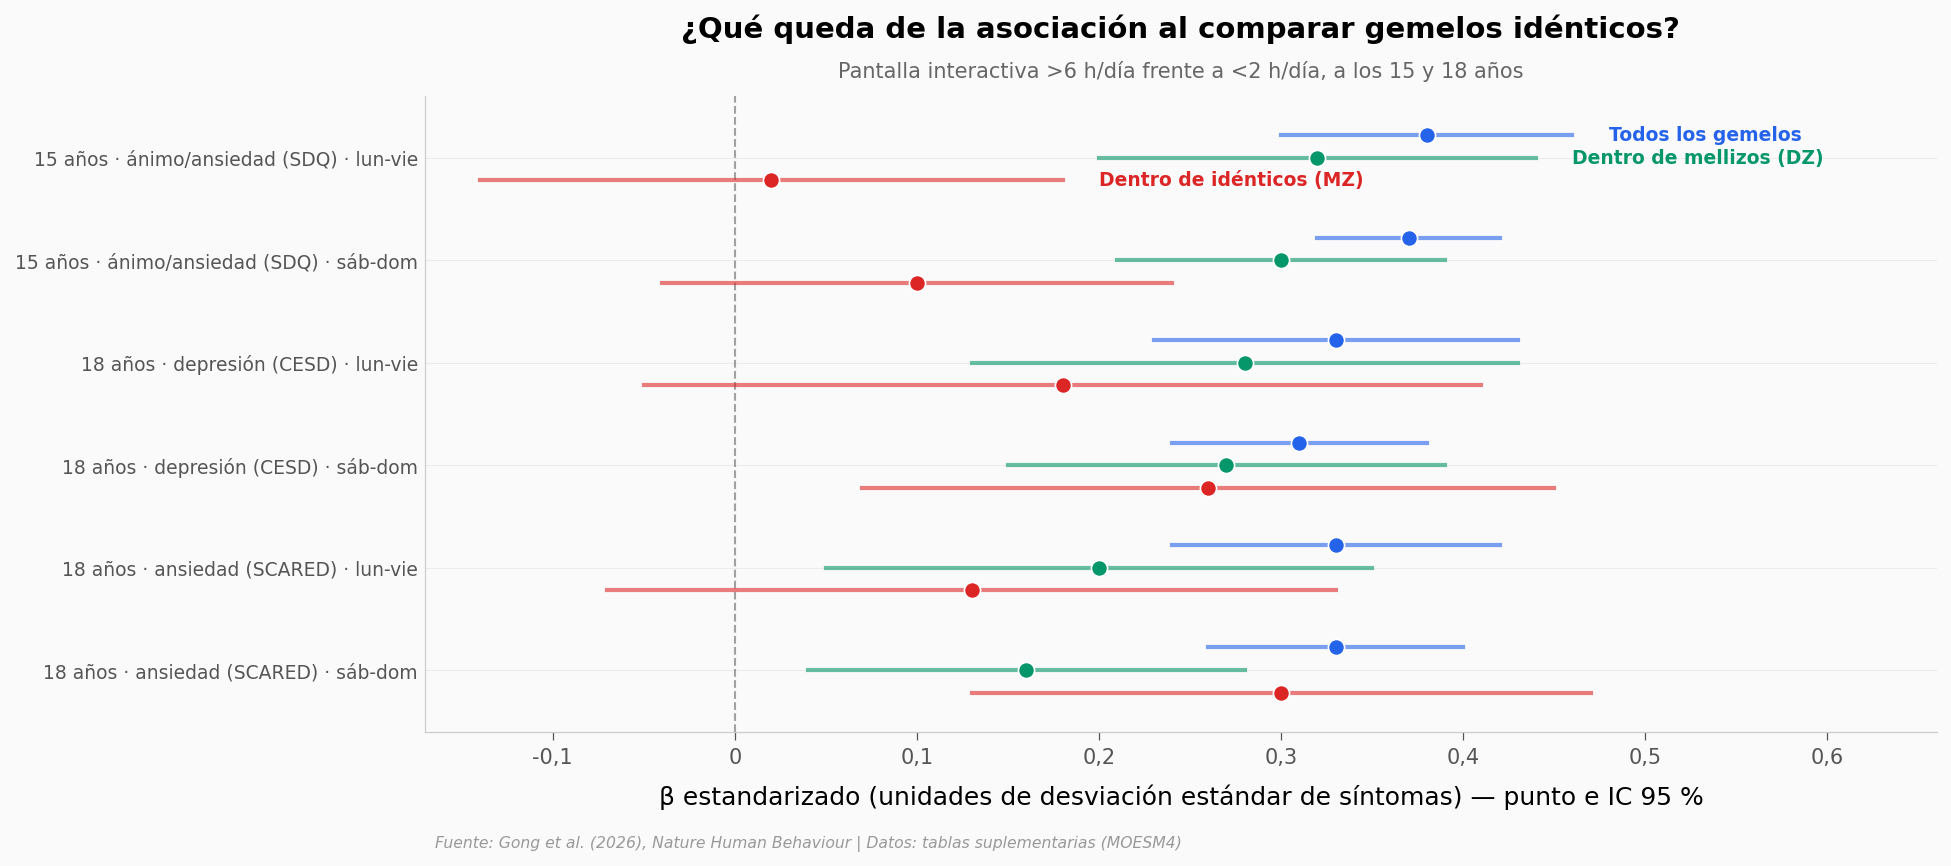

β idénticos < β todos en 6 de 6 comparaciones
Reducción hacia MZ: mediana 53 % (RIC 23–70 %; rango 9–95 %)
Ancho medio del IC 95 %: todos 0,15 · idénticos 0,36


In [2]:
# β intenso (NIVEL vs <2 h/día) en tres comparaciones: todos los gemelos, dentro de mellizos, dentro de idénticos
MODELOS = [('todos_ajustado', 'Todos los gemelos', COLOR_DATOS),
           ('dentro_dz', 'Dentro de mellizos (DZ)', COLOR_SECUNDARIO),
           ('dentro_mz', 'Dentro de idénticos (MZ)', COLOR_ALERTA)]
sel = trans[(trans.nivel == NIVEL) & (trans.tipo == TIPO) & trans.edad.isin([15, 18])]
filas = sel[['edad', 'desenlace', 'dia']].drop_duplicates().sort_values(['edad', 'desenlace', 'dia'], ascending=[True, False, True])

fig, ax = plt.subplots(figsize=(13, 5.5))
offs = {'todos_ajustado': 0.22, 'dentro_dz': 0.0, 'dentro_mz': -0.22}
etiquetas = []
for i, (_, f) in enumerate(filas.iterrows()):
    y0 = len(filas) - 1 - i
    etiquetas.append((y0, f"{f.edad} años · {DESENLACE[f.desenlace]} · {DIA[f.dia]}"))
    for m, nombre, color in MODELOS:
        r = sel[(sel.edad == f.edad) & (sel.desenlace == f.desenlace) & (sel.dia == f.dia) & (sel.modelo == m)].iloc[0]
        y = y0 + offs[m]
        ax.plot([r.ic_inf, r.ic_sup], [y, y], color=color, lw=2, alpha=0.6, zorder=4)
        ax.scatter(r.beta, y, color=color, s=60, edgecolors='white', linewidths=0.8, zorder=5)
        if i == 0:
            ax.text(r.ic_sup + 0.02, y, nombre, color=color, fontsize=9, fontweight='bold', va='center')
ax.axvline(0, color='#666666', lw=1, ls='--', alpha=0.6)
ax.set_yticks([e[0] for e in etiquetas])
ax.set_yticklabels([e[1] for e in etiquetas], fontsize=9)
ax.set_ylim(-0.6, len(filas) - 0.4)
ax.set_xlim(-0.17, 0.66)
ax.set_xlabel('β estandarizado (unidades de desviación estándar de síntomas) — punto e IC 95 %')
ax.xaxis.set_major_formatter(COMA)
ax.set_title('¿Qué queda de la asociación al comparar gemelos idénticos?', fontsize=14, fontweight='bold', pad=28)
ax.text(0.5, 1.03, f"Pantalla {'interactiva' if TIPO == 'interactivo' else 'pasiva'} {NIVEL.replace(' hours/day', ' h/día')} frente a <2 h/día, a los 15 y 18 años",
        transform=ax.transAxes, fontsize=10, color='#666666', ha='center')
fig.text(0.13, -0.03, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/hero_gemelos_beta.png', dpi=200, bbox_inches='tight')
plt.show()

piv = sel.pivot_table(index=['edad', 'desenlace', 'dia'], columns='modelo', values='beta')
red = (1 - piv.dentro_mz / piv.todos_ajustado) * 100
pr(f'β idénticos < β todos en {(piv.dentro_mz < piv.todos_ajustado).sum()} de {len(piv)} comparaciones')
pr(f'Reducción hacia MZ: mediana {red.median():.0f} % (RIC {red.quantile(.25):.0f}–{red.quantile(.75):.0f} %; rango {red.min():.0f}–{red.max():.0f} %)')
mzw = sel[sel.modelo == 'dentro_mz']
pr(f'Ancho medio del IC 95 %: todos {(sel[sel.modelo == "todos_ajustado"].eval("ic_sup - ic_inf")).mean():.2f}'
   f' · idénticos {(mzw.ic_sup - mzw.ic_inf).mean():.2f}')

A los 15 años, entre semana, los adolescentes con más de 6 horas diarias de pantalla interactiva tienen síntomas **0,38 desviaciones estándar** más altos que los de menos de 2 horas. Entre mellizos la diferencia casi no se mueve (0,32). Entre idénticos cae a **0,02** (IC 95 % −0,14 a 0,18; p = 0,79): la diferencia entre el gemelo que juega y chatea más y su gemelo no se distingue de cero.

El patrón se repite en las seis comparaciones con pantalla interactiva: el coeficiente dentro de idénticos siempre queda por debajo del de todos los gemelos. Pero cuánto baja varía mucho: la reducción mediana es del 53 % (la mitad central de los casos está entre 23 y 70 %), y va del 9 % al 95 %.

Ojo con lo que **no** dice esto. Los intervalos dentro de idénticos son entre 2,0 y 2,8 veces más anchos (ancho medio 0,36 frente a 0,15), porque solo aportan información los pares en que un gemelo usa mucho la pantalla y el otro poco. Un coeficiente no significativo no es lo mismo que un efecto cero.

## ¿Pasa lo mismo con la tele?

Repetimos la comparación con las 12 combinaciones de uso intenso (interactivo y pasivo, entre semana y fin de semana, 15 y 18 años).

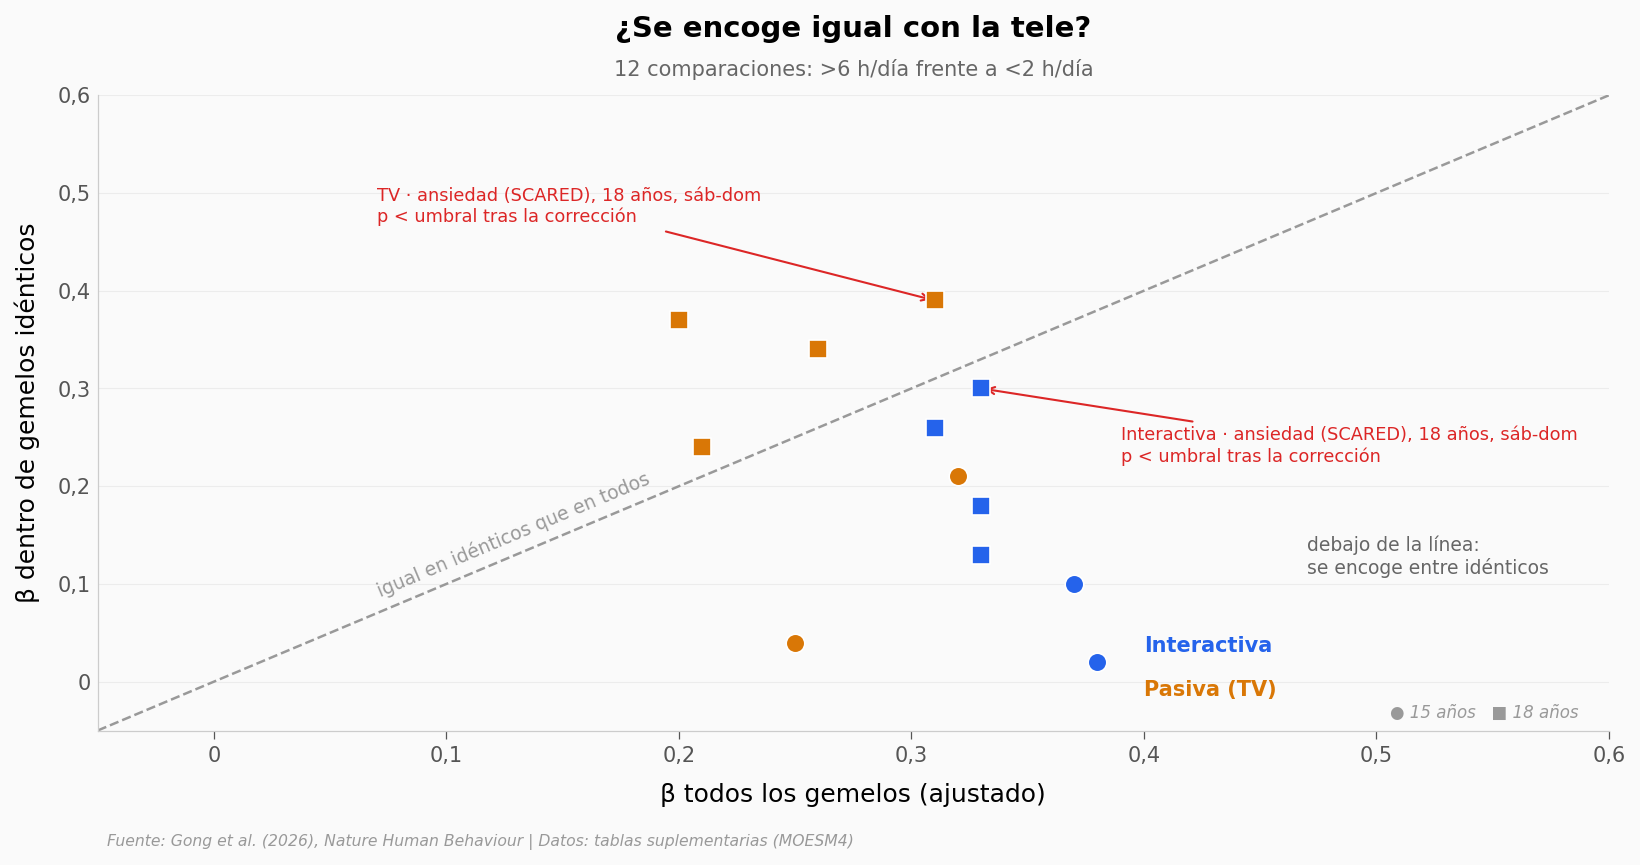

interactivo: β MZ < β todos en 6 de 6
pasivo: β MZ < β todos en 2 de 6
Significativas tras la corrección (todos): 11 de 12
Significativas tras la corrección (mellizos): 5 de 12
Significativas tras la corrección (idénticos): 2 de 12
Entre edades, significativas tras la corrección: todos 6 de 16 · dentro del par 0 de 16


In [3]:
intenso = trans[(trans.nivel == NIVEL) & trans.edad.isin([15, 18])]
pv = intenso.pivot_table(index=['edad', 'desenlace', 'tipo', 'dia'], columns='modelo', values='beta').reset_index()
pmz = intenso[intenso.modelo == 'dentro_mz'].set_index(['edad', 'desenlace', 'tipo', 'dia']).p
pv['p_mz'] = pv.set_index(['edad', 'desenlace', 'tipo', 'dia']).index.map(pmz)

fig, ax = plt.subplots(figsize=(13, 5.5))
lim = (-0.05, 0.6)
ax.plot(lim, lim, color='#999999', ls='--', lw=1.2)
ax.text(0.13, 0.145, 'igual en idénticos que en todos', color='#999999', fontsize=9, rotation=45,
        transform_rotates_text=True, rotation_mode='anchor', ha='center')
for tipo, color, nombre in [('interactivo', COLOR_DATOS, 'Interactiva (juegos, chat, internet)'),
                            ('pasivo', COLOR_REFERENCIA, 'Pasiva (TV, video)')]:
    for edad, marker in [(15, 'o'), (18, 's')]:
        d = pv[(pv.tipo == tipo) & (pv.edad == edad)]
        ax.scatter(d.todos_ajustado, d.dentro_mz, color=color, marker=marker, s=80,
                   edgecolors='white', linewidths=0.8, zorder=5)
sig = pv[pv.p_mz < UMBRAL_BY]
for _, r in sig.iterrows():
    dx, dy = (-0.24, 0.08) if r.tipo == 'pasivo' else (0.06, -0.075)
    ax.annotate(f"{'TV' if r.tipo == 'pasivo' else 'Interactiva'} · {DESENLACE[r.desenlace]}, {r.edad} años, {DIA[r.dia]}\np < umbral tras la corrección",
                xy=(r.todos_ajustado, r.dentro_mz), xytext=(r.todos_ajustado + dx, r.dentro_mz + dy),
                fontsize=8.5, color=COLOR_ALERTA, arrowprops=dict(arrowstyle='->', color=COLOR_ALERTA, lw=1))
ax.text(0.40, 0.03, 'Interactiva', color=COLOR_DATOS, fontsize=10, fontweight='bold')
ax.text(0.40, -0.015, 'Pasiva (TV)', color=COLOR_REFERENCIA, fontsize=10, fontweight='bold')
ax.text(0.98, 0.02, '● 15 años   ■ 18 años', transform=ax.transAxes, fontsize=8, color='#999999', ha='right', style='italic')
ax.text(0.47, 0.11, 'debajo de la línea:\nse encoge entre idénticos', color='#666666', fontsize=9, ha='left')
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel('β todos los gemelos (ajustado)')
ax.set_ylabel('β dentro de gemelos idénticos')
ax.xaxis.set_major_formatter(COMA); ax.yaxis.set_major_formatter(COMA)
ax.set_title('¿Se encoge igual con la tele?', fontsize=14, fontweight='bold', pad=28)
ax.text(0.5, 1.03, f"12 comparaciones: {NIVEL.replace(' hours/day', ' h/día')} frente a <2 h/día",
        transform=ax.transAxes, fontsize=10, color='#666666', ha='center')
fig.text(0.13, -0.03, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/todos_vs_identicos.png', dpi=200, bbox_inches='tight')
plt.show()

for tipo in ['interactivo', 'pasivo']:
    d = pv[pv.tipo == tipo]
    pr(f'{tipo}: β MZ < β todos en {(d.dentro_mz < d.todos_ajustado).sum()} de {len(d)}')
ptv = intenso.pivot_table(index=['edad', 'desenlace', 'tipo', 'dia'], columns='modelo', values='p')
for m, nombre in [('todos_ajustado', 'todos'), ('dentro_dz', 'mellizos'), ('dentro_mz', 'idénticos')]:
    pr(f'Significativas tras la corrección ({nombre}): {(ptv[m] < UMBRAL_BY).sum()} de {len(ptv)}')

# Seguimiento en el tiempo: uso a una edad → síntomas años después (dentro del par junta MZ y DZ)
ee = entre[entre.nivel == NIVEL].pivot_table(index=['edad_exposicion', 'edad_desenlace', 'desenlace', 'tipo', 'dia'],
                                             columns='modelo', values='p')
pr(f'Entre edades, significativas tras la corrección: todos {(ee.todos_ajustado < UMBRAL_BY).sum()} de {len(ee)}'
   f' · dentro del par {(ee.dentro_par < UMBRAL_BY).sum()} de {len(ee)}')

Con la tele la historia cambia: el coeficiente de los idénticos baja solo en 2 de 6 casos, y a los 18 años queda por **encima** del de todos los gemelos en las cuatro comparaciones. Tampoco hay un patrón limpio de "todo se esfuma": los dos únicos coeficientes entre idénticos que superan la corrección por pruebas múltiples son de ansiedad a los 18, en fin de semana, uno interactivo (β 0,30) y uno pasivo (β 0,39).

El seguimiento en el tiempo apunta en la misma dirección. Cuando el uso de pantallas a una edad se compara con los síntomas años después, 6 de 16 comparaciones intensas superan la corrección en todos los gemelos y **0 de 16** dentro del par (aquí, idénticos y mellizos juntos). El paper reporta también la flecha inversa: más síntomas a los 15 van de la mano con un poco más de pantalla interactiva en fin de semana a los 18 (razón de probabilidades, OR 1,04).

## ¿Y los diagnósticos clínicos?

Los síntomas son cuestionarios. Los registros suecos cuentan algo más duro: diagnósticos de depresión o ansiedad. En la cohorte de 9 años, el 11,5 % (2.523 de 21.797) recibió uno antes de los 22; en la de 15 años, el 17,7 % (2.843 de 16.027) antes de los 28.

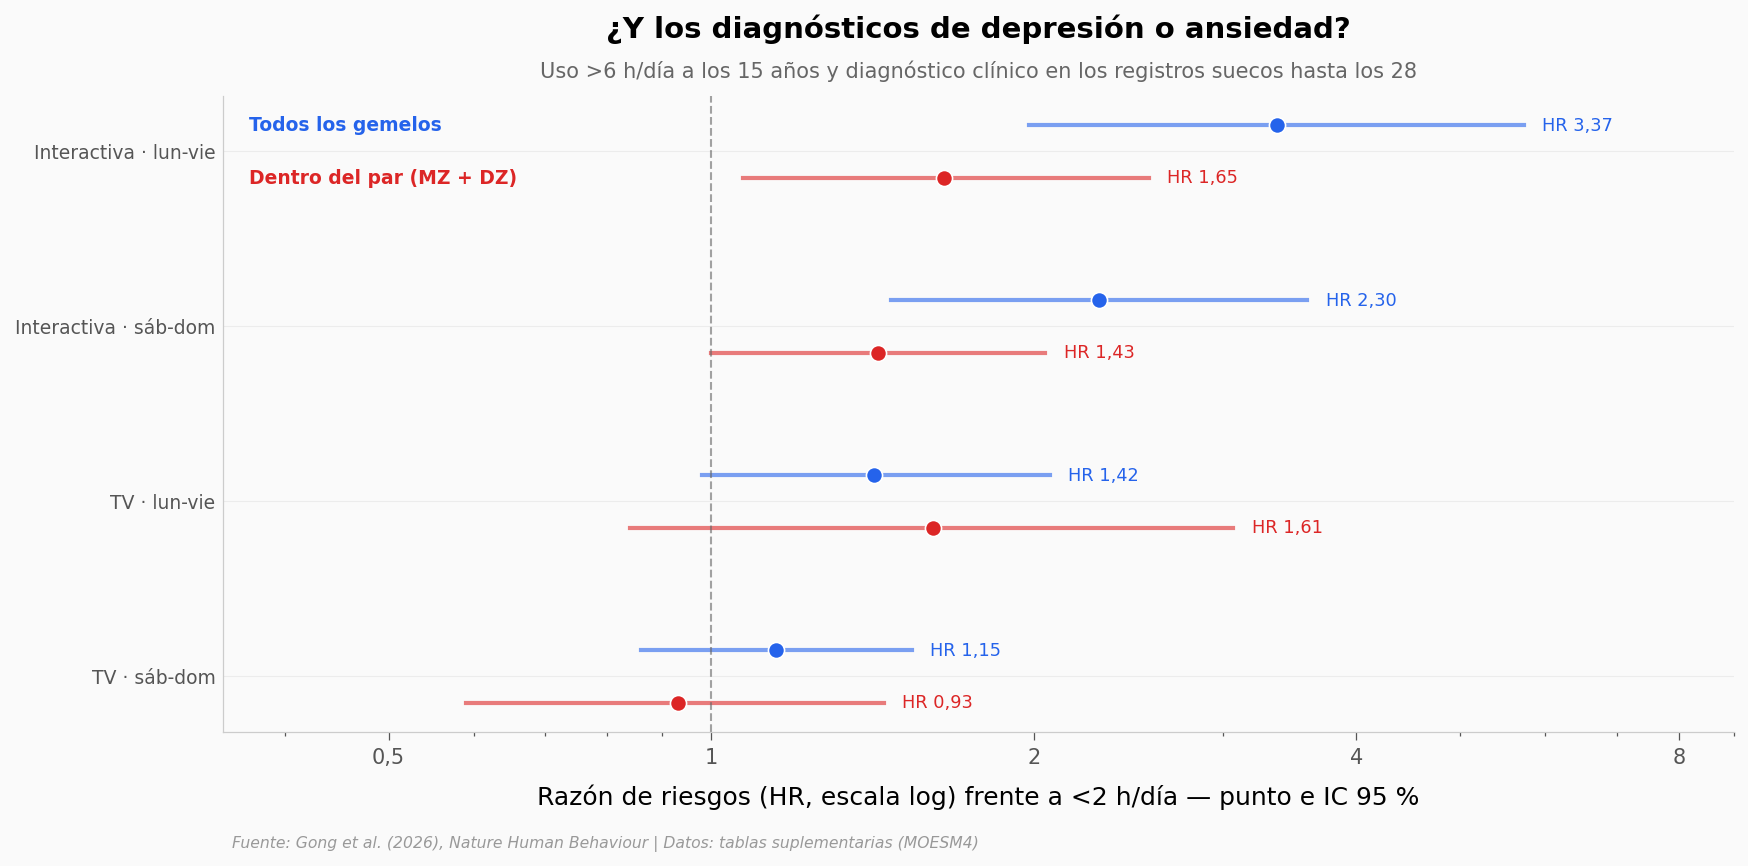

Interactiva lun-vie: tasa 42,3 vs 13,0 por mil persona-año (×3,25, crudo) · HR dentro del par 1,65 (1,07–2,56), p = 0,025, 453 pares discordantes
   Reducción de log(HR): 58,8 %
Interactiva sáb-dom: tasa 25,8 vs 13,0 por mil persona-año (×1,98, crudo) · HR dentro del par 1,43 (1,00–2,05), p = 0,051, 503 pares discordantes
   Reducción de log(HR): 57,1 %


In [4]:
c15 = clin[(clin.edad == 15) & (clin.desenlace == 'Depression / anxiety') & (clin.nivel == NIVEL)
           & clin.modelo.isin(['todos', 'dentro_par'])]
orden = [('interactivo', 'lun-vie'), ('interactivo', 'sab-dom'), ('pasivo', 'lun-vie'), ('pasivo', 'sab-dom')]
NOMBRE_TIPO = {'interactivo': 'Interactiva', 'pasivo': 'TV'}

fig, ax = plt.subplots(figsize=(13, 5.5))
for i, (tipo, dia) in enumerate(orden):
    y0 = len(orden) - 1 - i
    for m, color, dy, nombre in [('todos', COLOR_DATOS, 0.15, 'Todos los gemelos'),
                                 ('dentro_par', COLOR_ALERTA, -0.15, 'Dentro del par (MZ + DZ)')]:
        r = c15[(c15.tipo == tipo) & (c15.dia == dia) & (c15.modelo == m)].iloc[0]
        ax.plot([r.ic_inf, r.ic_sup], [y0 + dy] * 2, color=color, lw=2, alpha=0.6)
        ax.scatter(r.hr, y0 + dy, color=color, s=60, edgecolors='white', linewidths=0.8, zorder=5)
        ax.text(r.ic_sup * 1.04, y0 + dy, es(f'HR {r.hr:.2f}'), color=color, fontsize=8.5, va='center')
        if i == 0:
            ax.text(0.37, y0 + dy, nombre, color=color, fontsize=9, fontweight='bold', va='center', ha='left')
ax.axvline(1, color='#666666', lw=1, ls='--', alpha=0.6)
ax.set_xscale('log')
ax.set_xticks([0.5, 1, 2, 4, 8]); ax.xaxis.set_major_formatter(COMA)
ax.set_xlim(0.35, 9)
ax.set_yticks(range(len(orden)))
ax.set_yticklabels([f'{NOMBRE_TIPO[t]} · {DIA[d]}' for t, d in orden][::-1], fontsize=9)
ax.set_xlabel('Razón de riesgos (HR, escala log) frente a <2 h/día — punto e IC 95 %')
ax.set_title('¿Y los diagnósticos de depresión o ansiedad?', fontsize=14, fontweight='bold', pad=28)
ax.text(0.5, 1.03, 'Uso >6 h/día a los 15 años y diagnóstico clínico en los registros suecos hasta los 28',
        transform=ax.transAxes, fontsize=10, color='#666666', ha='center')
fig.text(0.13, -0.03, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/diagnosticos_hr.png', dpi=200, bbox_inches='tight')
plt.show()

for tipo, dia in orden[:2]:
    base = clin[(clin.edad == 15) & (clin.desenlace == 'Depression / anxiety') & (clin.tipo == tipo)
                & (clin.dia == dia) & (clin.modelo == 'referencia')].iloc[0]
    t = c15[(c15.tipo == tipo) & (c15.dia == dia) & (c15.modelo == 'todos')].iloc[0]
    dp = c15[(c15.tipo == tipo) & (c15.dia == dia) & (c15.modelo == 'dentro_par')].iloc[0]
    pr(f'{NOMBRE_TIPO[tipo]} {DIA[dia]}: tasa {t.tasa_x1000:.1f} vs {base.tasa_x1000:.1f} por mil persona-año (×{t.tasa_x1000 / base.tasa_x1000:.2f}, crudo)'
       f' · HR dentro del par {dp.hr:.2f} ({dp.ic_inf:.2f}–{dp.ic_sup:.2f}), p = {dp.p:.3f}, {int(dp.n_pares_discordantes)} pares discordantes')
    pr(f'   Reducción de log(HR): {(1 - np.log(dp.hr) / np.log(t.hr)) * 100:.1f} %')

Pasar más de 6 horas diarias con pantallas interactivas entre semana va de la mano con un ritmo de diagnósticos **3,37 veces** mayor (razón de riesgos, HR). Dentro del par baja a 1,65 (IC 1,07–2,56; p = 0,025): sigue por encima de 1, pero no supera la corrección por pruebas múltiples. Ojo: aquí "dentro del par" junta idénticos y mellizos para ganar tamaño, así que no separa genes de hogar como el análisis anterior. Con la tele, ni siquiera la comparación entre todos los gemelos sale clara.

## ¿Qué tan típica es la caída de 0,38 a 0,02?

La comparación del inicio es la más llamativa. ¿Es representativa? Juntamos las 48 comparaciones de las tablas (todas las edades, tipos y niveles de uso) y medimos cuánto cambia el coeficiente al pasar de todos los gemelos a los idénticos.

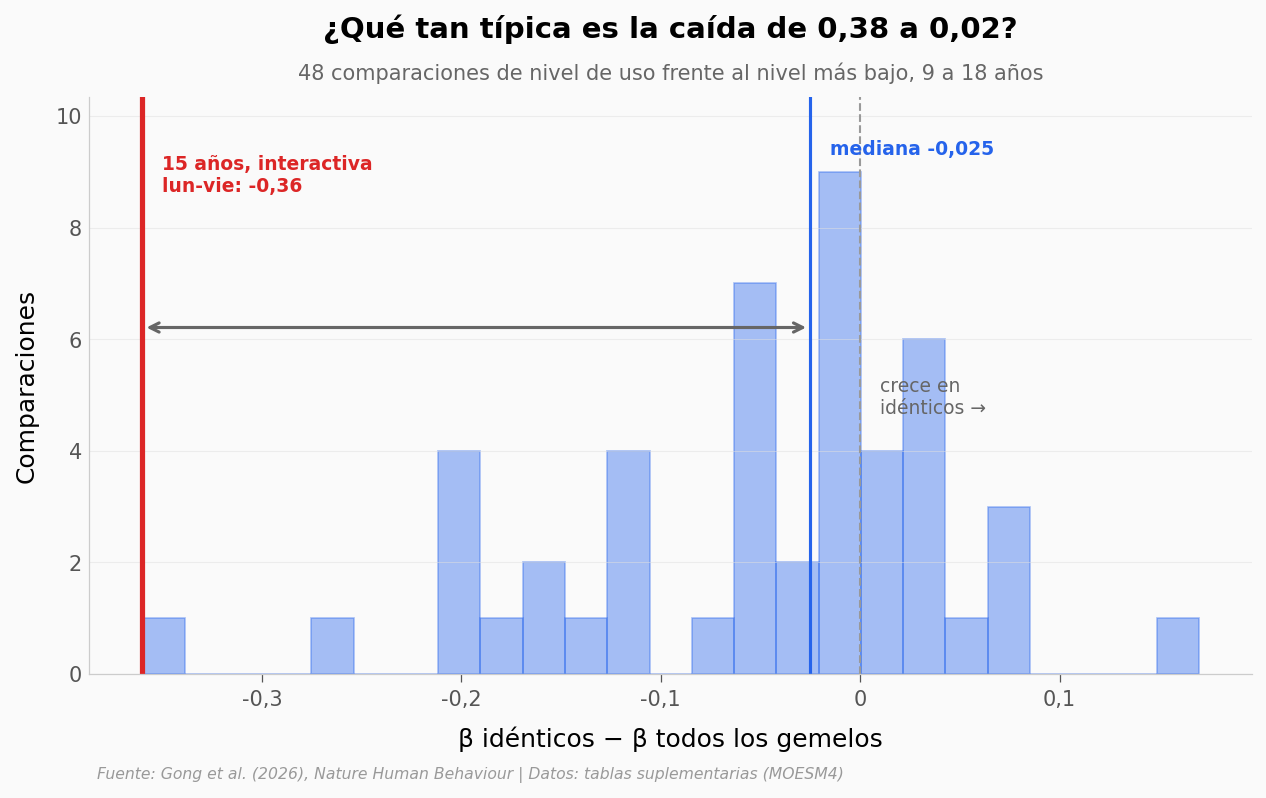

Bajan 32, suben 15, igual 1 de 48
Mediana -0,025 (RIC -0,113 a 0,013); distribución con cola hacia la izquierda
El protagonista (-0,36) es la caída más grande: mínimo = -0,36


In [5]:
cat = trans[~trans.nivel.isin(['continuous', 'per hour increase'])]
pc = cat.pivot_table(index=['edad', 'desenlace', 'exposicion', 'nivel'], columns='modelo', values='beta')
dif = (pc.dentro_mz - pc.todos_ajustado).dropna()
protagonista = pc.loc[(15, 'Depression/anxiety symptoms (SDQ emotion subscale)',
                       'Mon-Fri: playing games, chat, browsing internet', '>6 hours/day')]
valor_actual = protagonista.dentro_mz - protagonista.todos_ajustado
mediana = dif.median()

fig, ax = plt.subplots(figsize=(10, 5))
n, bins, patches = ax.hist(dif, bins=25, color=COLOR_DATOS, alpha=0.4, edgecolor=COLOR_DATOS, linewidth=0.8)
y_max = n.max() * 1.15
ax.set_ylim(0, y_max)
ax.axvline(0, color='#999999', lw=1, ls='--')
ax.axvline(mediana, color=COLOR_DATOS, linewidth=1.5)
ax.axvline(valor_actual, color=COLOR_ALERTA, linewidth=2.5)
ax.annotate('', xy=(valor_actual, y_max * 0.6), xytext=(mediana, y_max * 0.6),
            arrowprops=dict(arrowstyle='<->', color='#666666', lw=1.5))
ax.text(mediana + 0.01, y_max * 0.9, es(f'mediana {mediana:.3f}'), color=COLOR_DATOS, fontsize=9, fontweight='bold')
ax.text(valor_actual + 0.01, y_max * 0.9, es(f'15 años, interactiva\nlun-vie: {valor_actual:.2f}'),
        color=COLOR_ALERTA, fontsize=9, fontweight='bold', va='top')
ax.text(0.01, y_max * 0.45, 'crece en\nidénticos →', color='#666666', fontsize=9)
ax.xaxis.set_major_formatter(COMA)
ax.set_xlabel('β idénticos − β todos los gemelos')
ax.set_ylabel('Comparaciones')
ax.set_title('¿Qué tan típica es la caída de 0,38 a 0,02?', fontsize=14, fontweight='bold', pad=28)
ax.text(0.5, 1.03, f'{len(dif)} comparaciones de nivel de uso frente al nivel más bajo, 9 a 18 años',
        transform=ax.transAxes, fontsize=10, color='#666666', ha='center')
fig.text(0.13, -0.03, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/histograma_cambio_beta.png', dpi=200, bbox_inches='tight')
plt.show()

pr(f'Bajan {(dif < 0).sum()}, suben {(dif > 0).sum()}, igual {(dif == 0).sum()} de {len(dif)}')
pr(f'Mediana {mediana:.3f} (RIC {dif.quantile(.25):.3f} a {dif.quantile(.75):.3f}); distribución con cola hacia la izquierda')
pr(f'El protagonista ({valor_actual:.2f}) es la caída más grande: mínimo = {dif.min():.2f}')

La caída del protagonista es la más grande de las 48: la comparación típica cambia mucho menos (mediana −0,025; rango intercuartílico −0,113 a 0,013). En 32 de 48 el coeficiente baja al mirar idénticos y en 15 sube. Decir que la asociación "desaparece entre gemelos idénticos" describe bien el caso extremo, no el típico.

### Lo que los datos soportan

| Afirmación | ¿Soportada? | Detalle |
|------------|-------------|---------|
| Más de 6 h diarias de pantalla se asocia con más síntomas de ansiedad y depresión | ✅ | Todos los gemelos (ajustado): 11 de 12 comparaciones intensas significativas tras la corrección; β 0,20–0,38 a los 15 y 18. Observacional |
| Entre gemelos idénticos, la asociación con pantalla interactiva intensa se encoge | ✅ | 6 de 6 comparaciones; reducción mediana 53 % (RIC 23–70 %, rango 9–95 %) |
| Con la tele el patrón no se repite | ⚠️ | β idénticos menor solo en 2 de 6; a los 18 los cuatro β de idénticos superan al de todos |
| Entre idénticos la asociación desaparece del todo | ❌ | 2 de 12 siguen significativas (ansiedad, 18 años, fin de semana) y los IC son 1,8–2,8 veces más anchos: no significativo no es efecto cero |
| El uso intenso de pantalla interactiva va de la mano con más diagnósticos clínicos | ⚠️ | HR 3,37 (1,98–5,73) en todos; 1,65 (1,07–2,56; p = 0,025) dentro del par, que no supera la corrección |
| Las pantallas causan ansiedad o depresión | ❌ | Ni probado ni descartado: diseño observacional. Los autores ven evidencia limitada de un efecto causal claro; sus datos sugieren que factores genéticos y ambientales compartidos explican la asociación en parte |

> **Limitaciones:** solo tenemos tablas agregadas, no los datos individuales (protegidos por ley). Los coeficientes vienen redondeados a 2 decimales, así que los porcentajes de reducción recalculados difieren hasta 2,4 puntos de los del paper en las 12 comparaciones intensas, y hasta 13 puntos con niveles de uso bajos, donde los β rondan 0,05. Los modelos dentro del par tienen mucha menos potencia (4.434 gemelos idénticos a los 15, 3.318 a los 18). La recogida de datos arrancó en 2004, antes de que el teléfono inteligente fuera masivo, y el uso es autorreportado desde los 15 años (reporte de los padres a los 9).

## Ahora tú

1. **¿Pasa lo mismo con menos horas?** Cambia `NIVEL` a `'2-4 hours/day'` en la celda de configuración y vuelve a ejecutar la gráfica principal. ¿Se encoge la asociación igual que con más de 6 horas?
2. **¿Y si miramos la tele?** Cambia `TIPO` a `'pasivo'`. ¿Los idénticos siguen por debajo de todos los gemelos?
3. **¿La asociación es más fuerte en chicas que en chicos?** La celda de abajo compara los coeficientes por sexo en las 12 comparaciones intensas. Prueba a cambiar `NIVEL` y mira si la brecha se mantiene.

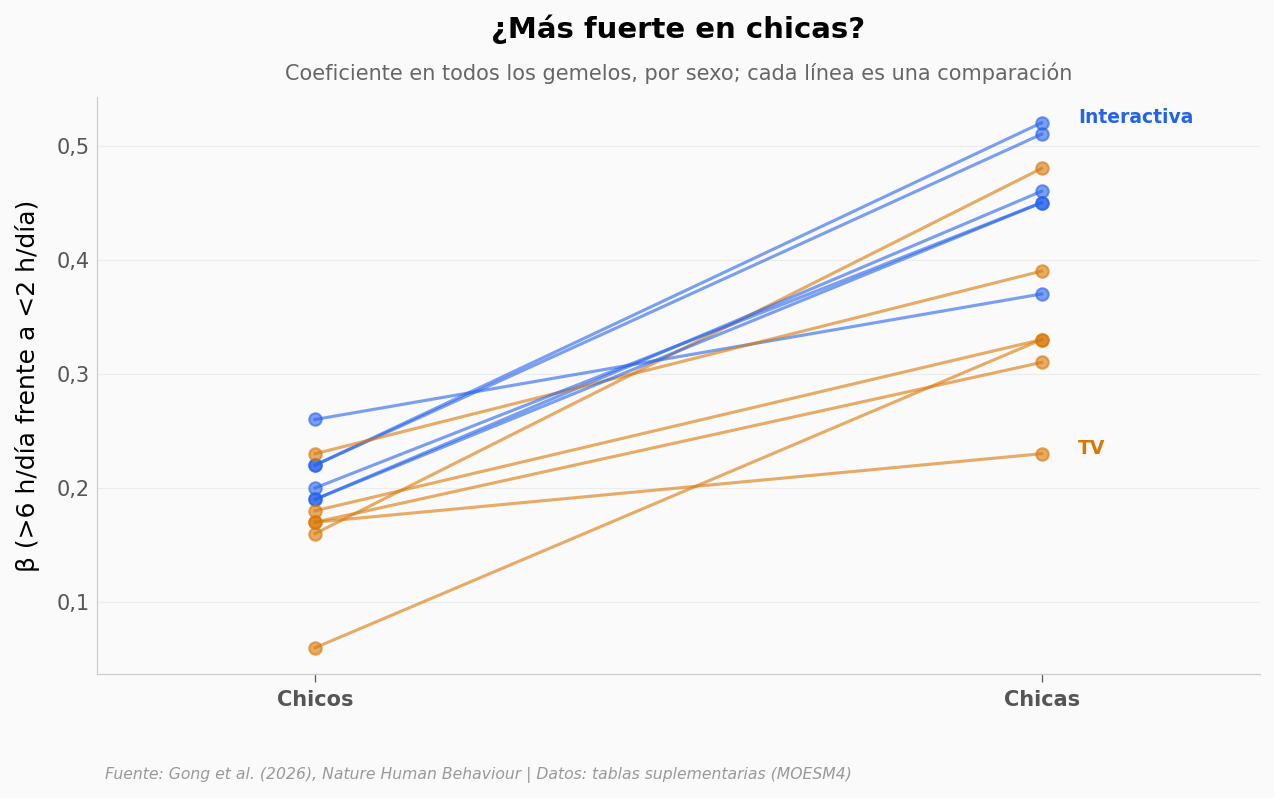

Chicas > chicos en 12 de 12 comparaciones
Interactiva: chicas β 0,37–0,52 (mediana 0,46), chicos 0,19–0,26 (mediana 0,21)
Cociente chicas/chicos: mediana 2,34 (rango 1,42–2,42)
p de interacción con el sexo: 5 de 12 comparaciones bajo el umbral


In [6]:
# --- EXPERIMENTA AQUÍ ---
# ¿La asociación es más fuerte en chicas? (todos los gemelos, por sexo)
sx = sexo[(sexo.nivel == NIVEL) & sexo.edad.isin([15, 18])]
ps = sx.pivot_table(index=['edad', 'desenlace', 'tipo', 'dia'], columns='sexo', values='beta')
pint = sx.groupby(['edad', 'desenlace', 'tipo', 'dia']).p_interaccion.first()

fig, ax = plt.subplots(figsize=(10, 5))
for i, (k, r) in enumerate(ps.iterrows()):
    color = COLOR_DATOS if k[2] == 'interactivo' else COLOR_REFERENCIA
    ax.plot([0, 1], [r.hombres, r.mujeres], color=color, alpha=0.6, lw=1.5, marker='o', markersize=6)
ax.set_xticks([0, 1]); ax.set_xticklabels(['Chicos', 'Chicas'], fontsize=10, fontweight='bold')
ax.set_xlim(-0.3, 1.3)
ax.yaxis.set_major_formatter(COMA)
ax.set_ylabel(f"β ({NIVEL.replace(' hours/day', ' h/día')} frente a <2 h/día)")
ax.text(1.05, ps.mujeres.max(), 'Interactiva', color=COLOR_DATOS, fontsize=9, fontweight='bold')
ax.text(1.05, ps.mujeres.min(), 'TV', color=COLOR_REFERENCIA, fontsize=9, fontweight='bold')
ax.set_title('¿Más fuerte en chicas?', fontsize=14, fontweight='bold', pad=28)
ax.text(0.5, 1.03, 'Coeficiente en todos los gemelos, por sexo; cada línea es una comparación',
        transform=ax.transAxes, fontsize=10, color='#666666', ha='center')
fig.text(0.13, -0.03, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/por_sexo.png', dpi=200, bbox_inches='tight')
plt.show()

inter = ps.xs('interactivo', level='tipo')
ratio = inter.mujeres / inter.hombres
pr(f'Chicas > chicos en {(ps.mujeres > ps.hombres).sum()} de {len(ps)} comparaciones')
pr(f'Interactiva: chicas β {inter.mujeres.min():.2f}–{inter.mujeres.max():.2f} (mediana {inter.mujeres.median():.2f}),'
   f' chicos {inter.hombres.min():.2f}–{inter.hombres.max():.2f} (mediana {inter.hombres.median():.2f})')
pr(f'Cociente chicas/chicos: mediana {ratio.median():.2f} (rango {ratio.min():.2f}–{ratio.max():.2f})')
pr(f'p de interacción con el sexo: {(pint < UMBRAL_BY).sum()} de {len(pint)} comparaciones bajo el umbral')

## Créditos

**Paper:** Gong et al. (2026). *Recreational screen use and internalizing problems from preadolescence to young adulthood in a longitudinal twin cohort with co-twin comparison*. Nature Human Behaviour. DOI: [10.1038/s41562-026-02607-0](https://doi.org/10.1038/s41562-026-02607-0) · Acceso abierto (CC BY 4.0).

**Datos:** tablas suplementarias 1–27 del paper (MOESM4). Los microdatos del Swedish Twin Registry no son públicos.

**Repositorio:** [Ciencia-a-Mordiscos/lab](https://github.com/Ciencia-a-Mordiscos/lab)

## Fuentes

**Paper**: [Recreational screen use and internalizing problems from preadolescence to young adulthood in a longitudinal twin cohort with co-twin comparison](https://doi.org/10.1038/s41562-026-02607-0)  
*Nature Human Behaviour, 2026-10-08* · acceso abierto (CC BY 4.0)

**Supplementary Material**: [Supplementary Tables 1–27 (MOESM4)](https://media.springernature.com/original/springer-static/esm/art%3A10.1038%2Fs41562-026-02607-0/MediaObjects/41562_2026_2607_MOESM4_ESM.xlsx)  
*Nature Human Behaviour, 2026-10-08*

*22 afirmaciones verificadas contra estas fuentes*